In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import os
import time
import copy
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd

os.environ["KERAS_BACKEND"] = "torch"
import keras_core as keras

Using PyTorch backend.


# The Perceptron and beyond

### Answer to Question 1.1
the link between a single perceptron and a linear regression model can be modeled using a linear activation function. something that outputs the input. i.e. y = x
by doing this the perceptron acts like a linear regression model. write the formula for the linear regression and then the single perceptron and then set activation function to the linear function for the report.

In this section, we consider a regression task where the underlying data generation process is as follows:
$$ y = - \sin{(0.8 * x)}$$

Note that in this example there is no noise in the data, a case that you will rarely encounter in practice.

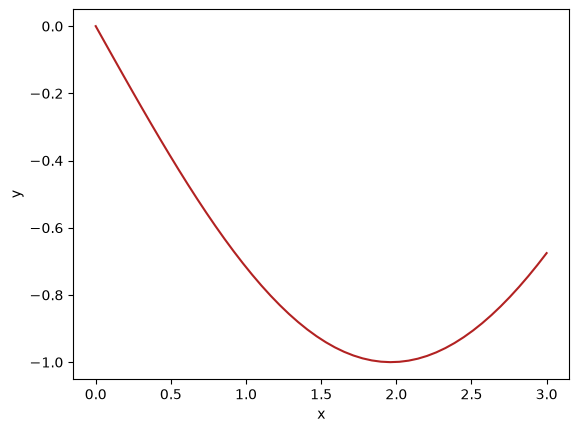

In [3]:
# Defining our dataset

x_train = torch.linspace(0, 3, 50)
y_train = -torch.sin(0.8 * x_train)

# Plotting the dataset

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick")
plt.show()

### A) 1.2
a linear model with first degree polynomials wouldn't be able to capture the relationship, because we can see in the image that the relationship is somewhat quadratic. but including higher order terms, especially second order terms can capture the relationship.

if we use linear model with only first degree terms, like x1, x2, etc. the model then would be underfitting because the true relationship has a quadratic nature in the specified input space. but we are not able to capture that, so the model is underfitted. (the error rate will be too high in the training set).

if we keep adding polynomials of higher and higher order, we might be overfitting the model, in a sense that we might model the training data too perfectly, and leave no room for generalization.

The following function can be used to instantiate the perceptron

In [4]:
def perceptron(input_shape=[1], units=1, activation=None):
    model = keras.Sequential(
        [
            keras.layers.Input(shape=input_shape),
            keras.layers.Dense(units=units, activation=activation),
        ]
    )
    return model


linear_model = perceptron()

# You can vizualize a summary of your model by commenting out the following line.
# Here it is an affine function in dimension 1, thus having two parameters.

linear_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape              ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)                 │          2 │
└─────────────────────────────────┴───────────────────────────┴────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

To fit a model in keras, one must first compile it, that is specify the loss and optimizer. Here they are respectively chosen as the mean squared error and gradient descent. Observe that the batch size is the same as the size of the training dataset, resulting in batch gradient descent.

You can play with the learning rate and number of epochs to understand how the training algorithm behaves.

Epoch 1/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - loss: 0.8565
Epoch 2/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3108
Epoch 3/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1502
Epoch 4/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0991
Epoch 5/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0798
Epoch 6/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0702
Epoch 7/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0639
Epoch 8/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0592
Epoch 9/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0554
Epoch 10/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0522
Epoch 11/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0495
Epoch 12/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0473
Epoch 13/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0454
Epoch 14/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0438
Epoch 15/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0424
Epoch 16/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/ste

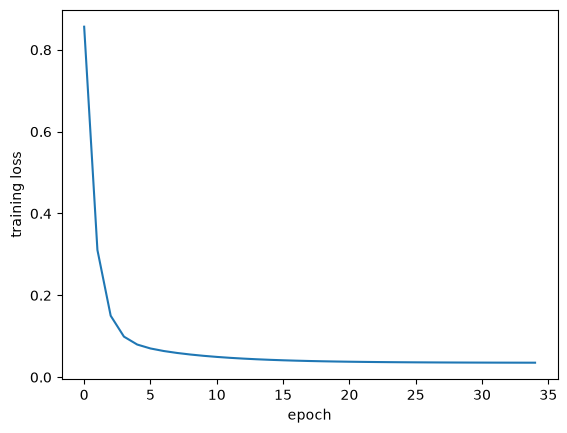

In [5]:
linear_model.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.SGD(learning_rate=0.2),
)
history = linear_model.fit(x_train, y_train, epochs=35, batch_size=50)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history.history["loss"])
plt.show()

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 12.0178
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.6466
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.2282
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.4933
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.2485
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.3554
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7145
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.2546
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9244
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6874
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5171
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3947
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3067
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2434
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1977
Epoch 16/100
1/1 ━━━━━━━━━━━━━━━━

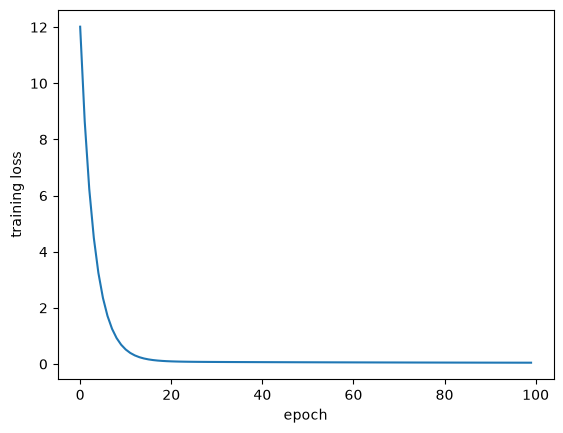

In [6]:
linear_model2 = perceptron()

linear_model2.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.SGD(learning_rate=0.02),
)
history2 = linear_model2.fit(x_train, y_train, epochs=100, batch_size=50)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history2.history["loss"])
plt.show()

the learning rate can be too small here, because the model seems to be stuck in a local minima. even increasing the number of epochs doesn't seem to help.

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.5666
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.5230
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4808
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4398
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.4001
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3616
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3243
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2881
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2529
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.2189
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1859
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1538
Epoch 13/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1228
Epoch 14/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0926
Epoch 15/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0634
Epoch 16/200
1/1 ━━━━━━━━━━━━━━━━

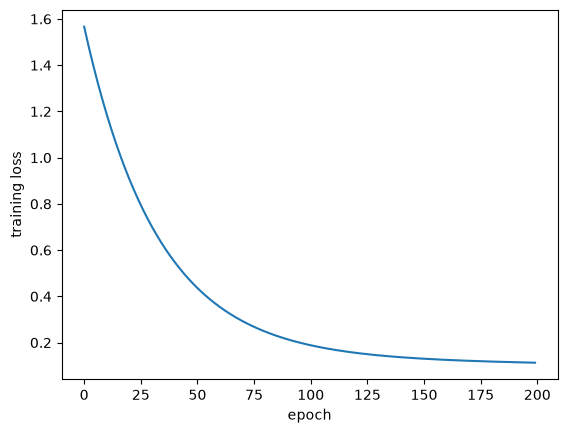

In [7]:
linear_model3 = perceptron()

linear_model3.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.SGD(learning_rate=0.002),
)
history3 = linear_model3.fit(x_train, y_train, epochs=200, batch_size=50)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history3.history["loss"])
plt.show()

the same issue as above

Epoch 1/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.4790
Epoch 2/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 60.7892
Epoch 3/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1592.7452
Epoch 4/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 41793.4883
Epoch 5/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1096697.2500
Epoch 6/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 28778316.0000
Epoch 7/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 755168960.0000
Epoch 8/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 19816314880.0000
Epoch 9/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 519997816832.0000
Epoch 10/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13645209665536.0000
Epoch 11/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 358062531543040.0000
Epoch 12/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9395881983868928.0000
Epoch 13/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 246556342838362112.0000
Epoch 14/35
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 6469859569

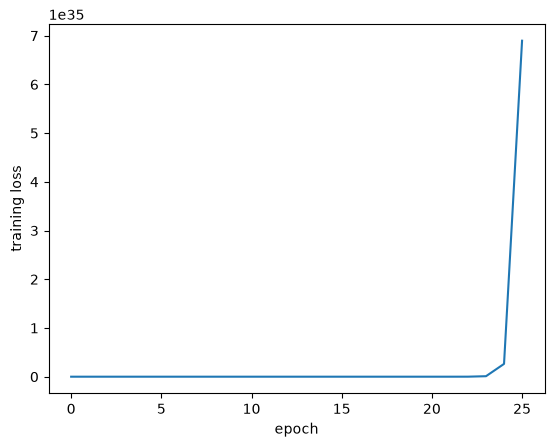

In [8]:
linear_model4 = perceptron()

linear_model4.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.SGD(learning_rate=0.8),
)
history4 = linear_model4.fit(x_train, y_train, epochs=35, batch_size=50)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history4.history["loss"])
plt.show()

### A)1.3
setting the learning rate too high results in very erratic behavior. it means that the model fails to converge and the weights are jumping around too much.

Having trained the model, we can now use it in prediction.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


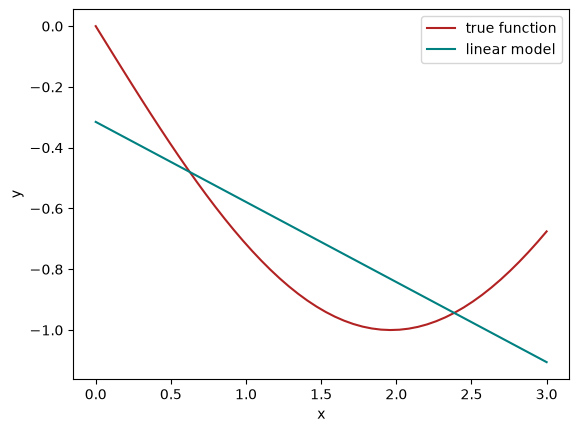

In [9]:
y_pred_linear = linear_model.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear, color="teal", label="linear model")
plt.legend()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


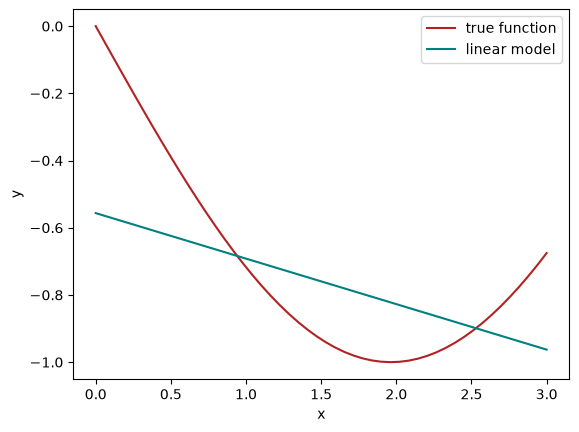

In [10]:
y_pred_linear2 = linear_model2.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear2, color="teal", label="linear model")
plt.legend()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


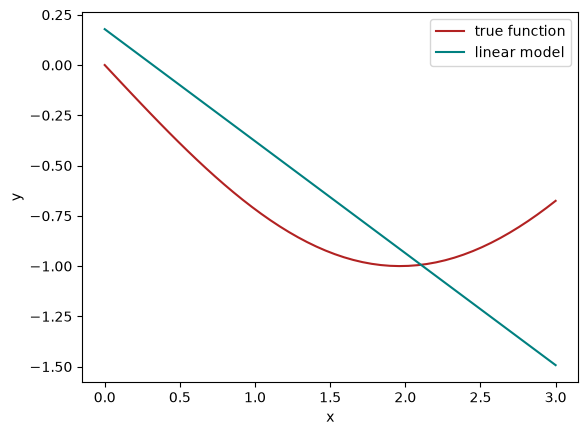

In [11]:
y_pred_linear3 = linear_model3.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear3, color="teal", label="linear model")
plt.legend()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


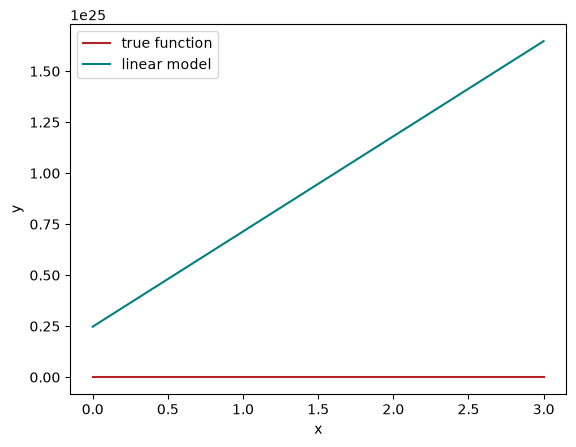

In [12]:
y_pred_linear4 = linear_model4.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear4, color="teal", label="linear model")
plt.legend()
plt.show()

Beyond this simple perceptron, we now consider a 2-layers neural network model.

In [13]:
def neural_net_2layers(input_shape=[1], units=16, activation="sigmoid"):
    model = keras.Sequential(
        [
            keras.layers.Input(shape=input_shape),
            keras.layers.Dense(units=units, activation=activation),
            keras.layers.Dense(units=1),
        ]
    )
    return model


net = neural_net_2layers(units=10)

net.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
)

You can train the model, and play with the hyperparameters to answer the questions.

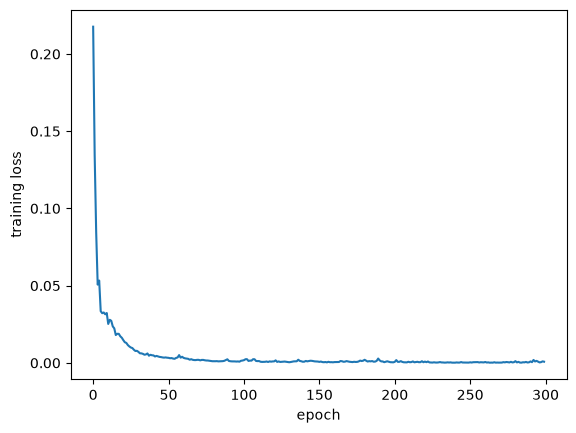

In [14]:
history = net.fit(x_train, y_train, epochs=300, batch_size=25, verbose=0)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history.history["loss"])
plt.show()

### A)1.4
sometimes the training loss (loss function value) increases because maybe the the jump for the weights were too much, which now results in higher loss value in this new epoch
#TODO: (I need to confirm this)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


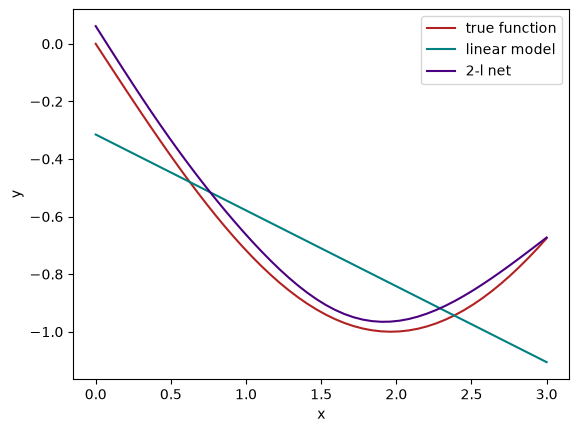

In [15]:
y_pred_2l = net.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear, color="teal", label="linear model")
plt.plot(x_train, y_pred_2l, color="indigo", label="2-l net")
plt.legend()
plt.show()

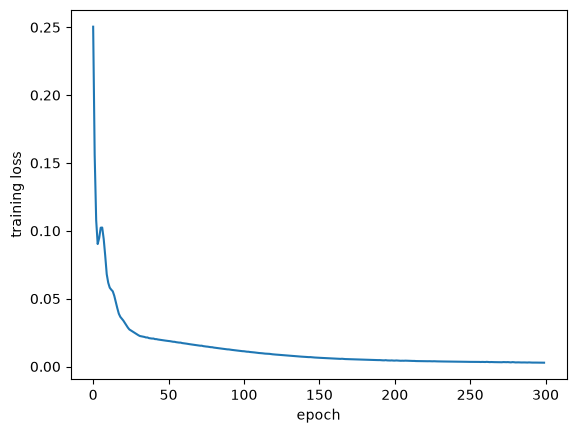

In [16]:
net2 = neural_net_2layers(units=10)

net2.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
)

history2 = net2.fit(x_train, y_train, epochs=300, batch_size=25, verbose=0)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history2.history["loss"])
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


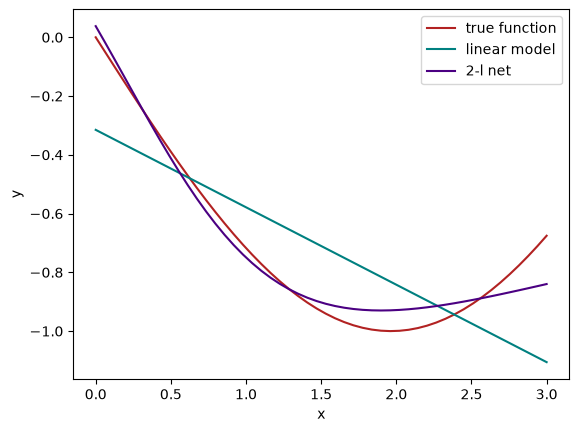

In [17]:
y_pred_22 = net2.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear, color="teal", label="linear model")
plt.plot(x_train, y_pred_22, color="indigo", label="2-l net")
plt.legend()
plt.show()

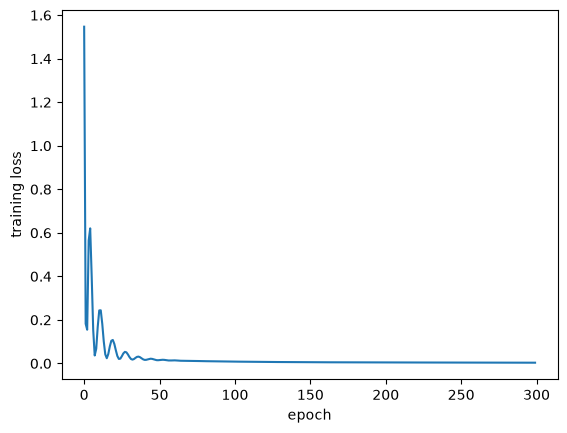

In [18]:
net3 = neural_net_2layers(units=10)

net3.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
)

history3 = net3.fit(x_train, y_train, epochs=300, batch_size=50, verbose=0)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history3.history["loss"])
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


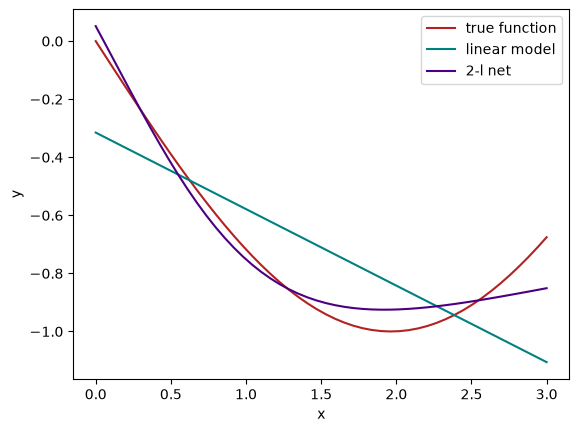

In [19]:
y_pred_23 = net3.predict(x_train)

plt.figure()
plt.xlabel("x")
plt.ylabel("y")
plt.plot(x_train, y_train, color="firebrick", label="true function")
plt.plot(x_train, y_pred_linear, color="teal", label="linear model")
plt.plot(x_train, y_pred_23, color="indigo", label="2-l net")
plt.legend()
plt.show()

# In the wild jungle of training algorithms

## Small model

We first start by defining a simple dataset based on a modified cosine surface. This will allows us to test small models, and in particular 2nd order optimization algorithms. While <tt>keras</tt> is high-level deep learning library, we will dive into the depths of <tt>pytorch</tt> to have more control over the optimization schemes.

/home/arad/ku-leuven/data-mining-neural-networks-projects/.venv/lib/python3.13/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


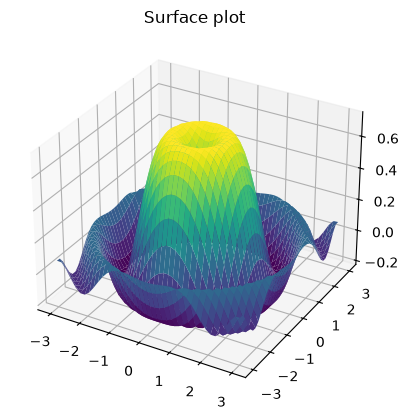

In [2]:
def f(x, y):
    return torch.sin(0.8 * (x**2 + y**2)) / (x**2 + y**2) ** (0.9)


noise = 0
mesh_size = 40
t = torch.linspace(-3, 3, mesh_size)
x, y = torch.meshgrid(t, t)
z = f(x, y) + noise * torch.randn(mesh_size, mesh_size)

fig = plt.figure()
ax = plt.axes(projection="3d")

ax.plot_surface(x, y, z, cmap="viridis", edgecolor="none")
ax.set_title("Surface plot")
plt.show()


# dataset creation
x_train = torch.vstack([x.ravel(), y.ravel()]).T
y_train = z.ravel()

### A)2.1
the noise in the data also back propagates if a gradient descent approach is used. the noise adds jitter to the surface of the loss function, so it takes more epochs to converge, and a smaller learning rate. because of the noise, it might bounce more around the local or global minima. if the effects of noise are too strong, we might need to have stronger regularization techniques.

The following class encodes the architecture of a neural network with two hidden layers, for when the input data is 2-dimensional. We provide a simplified <tt>fit</tt> method to train the neural network. You are encouraged to understand the code, and what executing the functions will return so as to draw legitimate conclusions about the experiments.

In [3]:
class Net3L(nn.Module):

    def __init__(self, n_neurons_l1=10, n_neurons_l2=10):
        super(Net3L, self).__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(2, n_neurons_l1),
            nn.ReLU(),
            nn.Linear(n_neurons_l1, n_neurons_l2),
            nn.ReLU(),
            nn.Linear(n_neurons_l2, 1),
        )

    def forward(self, x):
        return self.linear_relu_stack(x)

    def fit(self, x_train, y_train, optimizer, batch_size, n_epochs_max):
        # Instantiate the train loader
        train_data = TensorDataset(x_train, y_train)
        train_loader = DataLoader(
            dataset=train_data, batch_size=batch_size, shuffle=True
        )
        # Beginning the optimization algorithm
        loss_list = []
        for n_epochs in range(n_epochs_max):
            # We train for a fixed number of epochs
            for x_batch, y_batch in train_loader:

                def closure():
                    optimizer.zero_grad()
                    output = self.forward(x_batch)
                    loss = nn.MSELoss()(output.squeeze(-1), y_batch)
                    loss.backward()
                    return loss

                loss = optimizer.step(closure)
            loss_list.append(loss.item())
        return loss_list

The cell below gives an example of what happens when the training is done using the L-BFGS algorithm. It can be adapted to other algorithms by modifying the arguments passed to the <tt>fit</tt> method. 

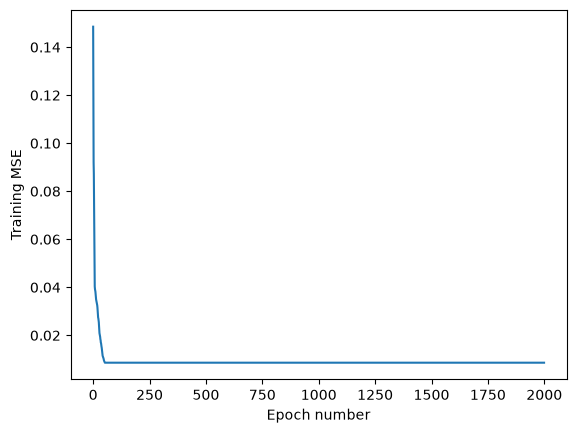

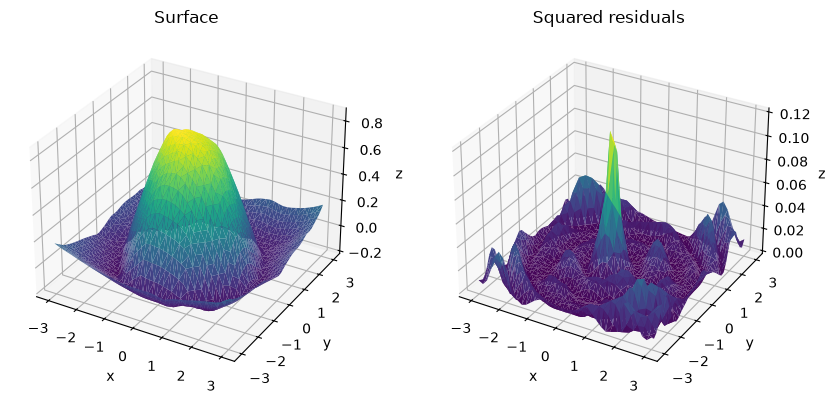

Training error: 0.008614257909357548


In [4]:
net = Net3L(50, 50)
loss_list = net.fit(
    x_train,
    y_train,
    torch.optim.LBFGS(
        net.parameters(), lr=1, max_iter=1, line_search_fn="strong_wolfe"
    ),
    1600,
    2000,
)

plt.figure()
plt.xlabel("Epoch number")
plt.ylabel("Training MSE")
plt.plot(loss_list)
plt.show()

y_pred = net(x_train)

fig, ax = plt.subplots(1, 2, figsize=(10, 10), subplot_kw={"projection": "3d"})
#
ax[0].plot_trisurf(
    x_train[:, 0],
    x_train[:, 1],
    y_pred.detach().numpy().squeeze(-1),
    vmin=y_train.min(),
    cmap=cm.viridis,
)
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_zlabel("z")
ax[0].set_title("Surface")
#
ax[1].plot_trisurf(
    x_train[:, 0],
    x_train[:, 1],
    (y_pred.detach().squeeze(-1) - y_train) ** 2,
    vmin=0,
    cmap=cm.viridis,
)
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_zlabel("z")
ax[1].set_title("Squared residuals")
plt.show()

print("Training error:", (nn.MSELoss()(y_pred.squeeze(-1), y_train)).item())

In [5]:
# Example with a list of optimizers
net = Net3L(50, 50)
# We create copies of this net so that every optimizer starts with the same initialization.
net_list = [copy.deepcopy(net) for i in range(5)]
# The number of epochs and other hyperparameters can (and should) be adapted to the point you're trying to make.
n_epochs = 2500
optimizer_list = [
    torch.optim.SGD(params=net_list[0].parameters(), lr=0.05),
    torch.optim.SGD(params=net_list[1].parameters(), lr=0.1),
    torch.optim.SGD(
        params=net_list[2].parameters(), lr=0.1, momentum=0.9, nesterov=True
    ),
    torch.optim.Adam(params=net_list[3].parameters()),
    torch.optim.LBFGS(
        params=net_list[4].parameters(), lr=1, max_iter=1, line_search_fn="strong_wolfe"
    ),
]
batch_sizes_list = [1600, 40, 400, 400, 1600]
times_list = []
loss_meta_list = []

for i, optimizer in enumerate(optimizer_list):
    t0 = time.time()
    loss_list = net_list[i].fit(
        x_train,
        y_train,
        optimizer=optimizer,
        batch_size=batch_sizes_list[i],
        n_epochs_max=n_epochs,
    )
    t1 = time.time()
    times_list.append(t1 - t0)
    loss_meta_list.append(loss_list)

In [7]:
labels = [
    "Batch GD (lr=0.05, bs=1600)",
    "Mini-batch SGD (lr=0.1, bs=40)",
    "NAG / Momentum (lr=0.1, bs=400)",
    "Adam (bs=400)",
    "L-BFGS (lr=1, bs=1600)",
]

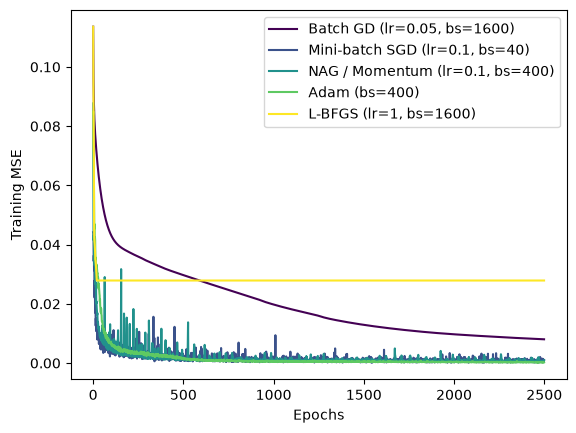

Respective times: [13.165027141571045, 30.67023253440857, 24.860914707183838, 25.17002034187317, 15.164837121963501]


In [10]:
colors = cm.viridis(torch.linspace(0, 1, 5))
plt.figure()
plt.xlabel("Epochs")
plt.ylabel("Training MSE")
for i in range(5):
    plt.plot(loss_meta_list[i], color=colors[i], label=labels[i])
plt.legend(loc="upper right", frameon=True)
plt.show()
#
print("Respective times:", times_list)

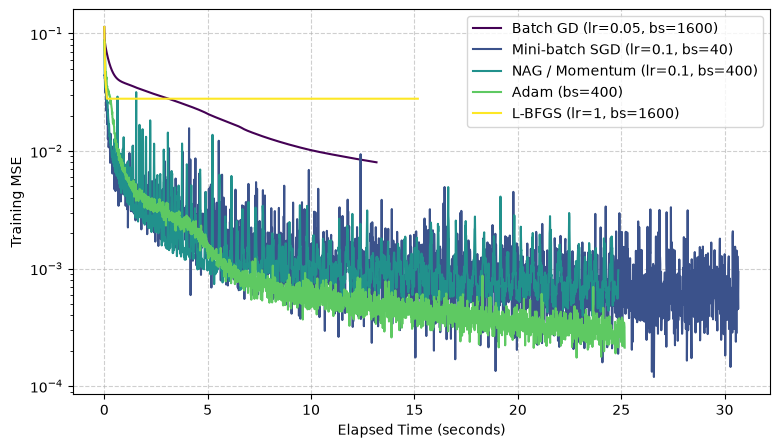

In [11]:
labels = [
    "Batch GD (lr=0.05, bs=1600)",
    "Mini-batch SGD (lr=0.1, bs=40)",
    "NAG / Momentum (lr=0.1, bs=400)",
    "Adam (bs=400)",
    "L-BFGS (lr=1, bs=1600)",
]

colors = cm.viridis(torch.linspace(0, 1, 5))

plt.figure(figsize=(9, 5))
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Training MSE")

for i in range(5):
    # Create time steps spanning from 0 to total runtime for this optimizer
    time_axis = np.linspace(0, times_list[i], len(loss_meta_list[i]))
    plt.plot(time_axis, loss_meta_list[i], color=colors[i], label=labels[i])

plt.yscale("log")
plt.legend(loc="upper right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Towards a bigger model

We now switch to a bigger model, used to perform classification over the MNIST dataset. This example is widely known in the machine learning community, and we follow the code in the footsteps of François Chollet, the creator of the <tt>keras</tt> library (https://keras.io/examples/vision/mnist_convnet/). 

In [12]:
# Model / data parameters
num_classes = 10
input_shape = (28, 28, 1)

# Load the data and split it between train and test sets
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale images to the [0, 1] range
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [13]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

The following cell deals with the training of the model. Can you change the optimizer while still retaining the capabilities of the model trained with adam ?

In [14]:
batch_size = 128
epochs = 15

# Modify the optimizer here
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7645 - loss: 0.7536 - val_accuracy: 0.9757 - val_loss: 0.0884
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9621 - loss: 0.1230 - val_accuracy: 0.9843 - val_loss: 0.0582
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9714 - loss: 0.0895 - val_accuracy: 0.9868 - val_loss: 0.0504
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9771 - loss: 0.0743 - val_accuracy: 0.9893 - val_loss: 0.0408
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9800 - loss: 0.0632 - val_accuracy: 0.9897 - val_loss: 0.0412
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9826 - loss: 0.0549 - val_accuracy: 0.9905 - val_loss: 0.0361
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9836 - loss: 0.0534 - val_accuracy: 0.9895 - val_loss: 0.0371
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9842 - loss: 0.0496 - val_accuracy: 0.

In [23]:
score = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:\t{score[0]:.4f}")
print(f"Test accuracy:\t{score[1]:.4f}")

Test loss:	0.0281
Test accuracy:	0.9901


In [17]:
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import GridSearchCV

In [20]:
def get_cnn():
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
            keras.layers.MaxPooling2D(pool_size=(2, 2)),
            keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
            keras.layers.MaxPooling2D(pool_size=(2, 2)),
            keras.layers.Flatten(),
            keras.layers.Dropout(0.5),
            keras.layers.Dense(num_classes, activation="softmax"),
        ]
    )
    return model


clf = KerasClassifier(
    model=get_cnn,
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.SGD,
    optimizer__learning_rate=0.01,
    optimizer__momentum=0.0,
    metrics=["accuracy"],
    epochs=15,
    batch_size=128,
    verbose=0,
)

param_grid = {
    "optimizer__learning_rate": [0.001, 0.01, 0.1],
    "optimizer__momentum": [0.0, 0.9],
}

grid = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring="accuracy")
grid_result = grid.fit(x_train, y_train)

print(
    f"Best SGD: {grid_result.best_score_:.4f} using {grid_result.best_params_}"
)

Best SGD: 0.9892 using {'optimizer__learning_rate': 0.1, 'optimizer__momentum': 0.9}


In [22]:
model2 = grid_result.best_estimator_.model_

score2 = model2.evaluate(x_test, y_test)

print(f"Test Loss:\t{score2[0]:.4f}")
print(f"Test Accuracy: {score2[1]:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9904 - loss: 0.0302
Test Loss:	0.0260
Test Accuracy: 0.9914


In [24]:
clf_adadelta = KerasClassifier(
    model=get_cnn,
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adadelta,
    metrics=["accuracy"],
    epochs=15,
    batch_size=128,
    verbose=0,
)

param_grid_adadelta = {
    "optimizer__learning_rate": [0.1, 0.5, 1.0],
    "optimizer__rho": [0.9, 0.95],
}

grid_adadelta = GridSearchCV(
    estimator=clf_adadelta,
    param_grid=param_grid_adadelta,
    cv=5,
    scoring="accuracy",
)
grid_adadelta_result = grid_adadelta.fit(x_train, y_train)

print(
    f"Best Adadelta: {grid_adadelta_result.best_score_:.4f} using {grid_adadelta_result.best_params_}"
)

Best Adadelta: 0.9884 using {'optimizer__learning_rate': 1.0, 'optimizer__rho': 0.95}


In [25]:
model3 = grid_adadelta_result.best_estimator_.model_
score3 = model3.evaluate(x_test, y_test)

print(f"Test Loss:\t{score3[0]:.4f}")
print(f"Test Accuracy: {score3[1]:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9903 - loss: 0.0263
Test Loss:	0.0219
Test Accuracy: 0.9920


# A personal regression example

For this exercise, you will work on a dataset that is built from your personal student number as indicated in the assignment.

In [30]:
data = pd.read_csv("data.csv", header=None).values.T


def dataset_generation(d1, d2, d3, d4, d5):
    T_new = (
        d1 * data[:, 2]
        + d2 * data[:, 3]
        + d3 * data[:, 4]
        + d4 * data[:, 5]
        + d5 * data[:, 6]
    ) / (d1 + d2 + d3 + d4 + d5)
    return T_new


x_values = data[:, 0:2]

# Put your own (decreasingly ordered) student number in the function

T_new = dataset_generation(8, 7, 6, 4, 3)

# Random subsampling to get the working dataset
idx = np.random.permutation(13600)

# training set
x_train = x_values[idx[0:2000]]
y_train = T_new[idx[0:2000]]

# test set
x_test = x_values[idx[2000:3000]]
y_test = T_new[idx[2000:3000]]


print("Number of training datapoints:", x_train.shape[0])
print("Number of testing datapoints:", x_test.shape[0])

Number of training datapoints: 2000
Number of testing datapoints: 1000


You can now plot the surface of the dataset. (Hint: use the function <tt> plot_trisurf </tt>)

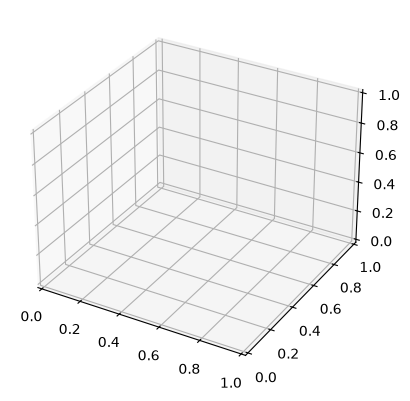

In [31]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
# TODO
plt.show()

In the following, we give an example of how to train a model. When you train yours, do not forget to validate it ! Hint: it is not enough to look at the training error. The hyperparameter values have voluntarily be set to give suboptimal results, you can do better than the proposed architecture !

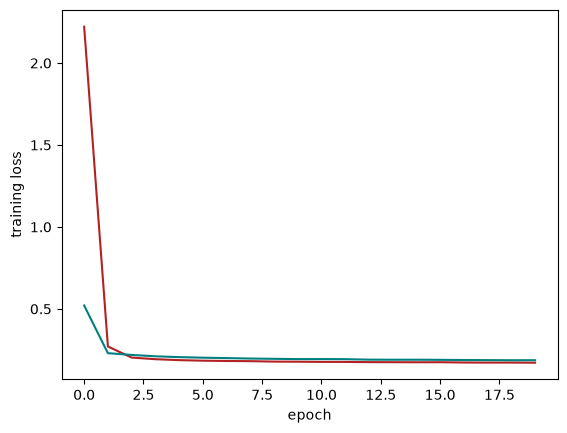

Last training error: 0.17181752622127533
Last validation error: 0.18705923855304718


In [32]:
net = keras.Sequential(
    [
        keras.layers.Input(shape=[x_train.shape[1]]),
        keras.layers.Dense(units=3, activation="tanh"),
        keras.layers.Dense(units=1),
    ]
)

net.compile(
    loss=keras.losses.MeanSquaredError(),
    optimizer=keras.optimizers.Adam(learning_rate=0.05),
)

callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2)
history = net.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    callbacks=[callback],
    verbose=0,
)

plt.figure()
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.plot(history.history["loss"], color="firebrick")
plt.plot(history.history["val_loss"], color="teal")
plt.show()
print("Last training error:", history.history["loss"][-1])
print("Last validation error:", history.history["val_loss"][-1])

Once a model is trained, you can use it to assess the final performance of the model on the test set.

In [33]:
y_pred = net.predict(x_test)
print("Final test error:", 0.5 * ((y_pred - y_test) ** 2).mean())

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step      
Final test error: 0.07869955394649511
